# Contrast maps: land-cover change, BVOC emission source, PD → FUT (no artefact correction)

Maps of three groups of contrasts. Each row of a figure is one contrast, each column one variable.
**Raw differences only:** the fBVOC prescription artefact (art_P = CTRL_P_fBVOCctrlP − CTRL_P) is **not** added. See *Artefact* below for which rows it affects.

**Runs** (new CO₂-fix chain, 2001–2014, first 12 months dropped): processed files `data/processed-data/postprocessing/<alias>_<atm|lnd>_<CAT>_2001-2014.nc`. The case names are printed in §0.

**Method.** Paired yearly differences (14 years; run 1 − run 2 in the same year). Map = mean over years. Hatching = **not** significant (cell-wise paired t-test, FDR α = 0.10 within ≥45°N). The number under each map = area-weighted mean ≥45°N ± 95 % t-interval across years. Each panel has its own colourbar, because the rows differ a lot in size.

**Wording.** The fixed-emission contrasts are **not** "pure biophysical" effects: with BVOC emissions prescribed, the altered land surface can still change chemistry, transport and removal.

**Artefact (what "without the artefact" means here)**

| Contrast type | Rows | Artefact in the raw difference |
|---|---|---|
| interactive − interactive | Q1 rows 1, 4; all of Q3 | none |
| interactive − prescribed | Q1 rows 2, 3, 5, 6; Q2 rows 3, 4 | **yes**: contains ± art_P (old-chain PD test: SOA +3 %) |
| prescribed − prescribed | Q2 rows 1, 2 | largely cancels (b): both runs use a climatology; it remains only if the artefact depends on the emission field |

Outputs: `contrast_maps_uncorrected_outputs/figures/`, `…/tables/`.

In [1]:
import sys
from pathlib import Path
REPO = Path.cwd().parents[1]
sys.path.insert(0, str(REPO / "src"))   # repo src/, no pip install needed

from dataclasses import replace
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

set_default_style()
pd.set_option("display.width", 220, "display.max_rows", 300, "display.max_colwidth", 60)
START_YEAR, END_YEAR = 2001, 2014
OUT = Path.cwd() / "contrast_maps_uncorrected_outputs"
FIGDIR, TABLES = OUT / "figures", OUT / "tables"
for d in (FIGDIR, TABLES):
    d.mkdir(parents=True, exist_ok=True)

# (run 1, run 2, short meaning) per question; row order as in the tables below
QUESTIONS = {
    "Q1-LCC-effect": [
        ("LCC_PD", "CTRL_PD", "total LCC effect, PD"),
        ("LCC_PD", "LCC_PD_fBVOCctrlPD", "BVOC emissions allowed to change, PD"),
        ("LCC_PD_fBVOCctrlPD", "CTRL_PD", "LCC with CTRL_PD emissions, PD"),
        ("LCC_FUT", "CTRL_FUT", "total LCC effect, FUT"),
        ("LCC_FUT", "LCC_FUT_fBVOCctrlFUT", "BVOC emissions allowed to change, FUT"),
        ("LCC_FUT_fBVOCctrlFUT", "CTRL_FUT", "LCC with CTRL_FUT emissions, FUT"),
    ],
    "Q2-FUT-emission-source": [
        ("LCC_FUT_fBVOClccPD", "LCC_FUT_fBVOCctrlPD", "PD LCC-induced emission change, under FUT"),
        ("LCC_FUT_fBVOCctrlFUT", "LCC_FUT_fBVOCctrlPD", "PD → FUT emission change, CTRL land"),
        ("LCC_FUT", "LCC_FUT_fBVOClccPD", "FUT (interactive) vs PD LCC emissions"),
        ("LCC_FUT", "LCC_FUT_fBVOCctrlPD", "CTRL_PD → interactive LCC_FUT emissions"),
    ],
    "Q3-PD-to-FUT": [
        ("CTRL_FUT", "CTRL_PD", "PD → FUT, control land"),
        ("LCC_FUT", "LCC_PD", "PD → FUT, changed land"),
        ("LCC_FUT", "CTRL_PD", "PD → FUT + land-cover change"),
    ],
}
ROWS = {q: [(a, b) for a, b, _ in rows] for q, rows in QUESTIONS.items()}

## 0. Inputs: case names and year spans
Each alias must point to a new-chain case (suffix `-20261028`, `-20261029` or `-20261031`) and cover 2001–2014.

In [2]:
aliases = sorted({a for rows in ROWS.values() for r in rows for a in r})
rows = []
for alias in aliases:
    ds = fm.open_class(alias, "RADIATIVE", START_YEAR, END_YEAR)
    t = ds["time"].dt
    rows.append(dict(alias=alias, case=ds.attrs.get("casename", "?"),
                     first=f"{int(t.year[0])}-{int(t.month[0]):02d}", last=f"{int(t.year[-1])}-{int(t.month[-1]):02d}",
                     n_months=ds.sizes["time"]))
inputs = pd.DataFrame(rows)
old = inputs[~inputs.case.str.contains(r"-2026(?:1028|1029|1031)$")]
assert old.empty, f"not on the new chain:\n{old}"
assert (inputs.n_months == 12 * (END_YEAR - START_YEAR + 1)).all()
inputs.to_csv(TABLES / "inputs.csv", index=False)
inputs

,alias,case,first,last,n_months
0,CTRL_FUT,NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028,2001-01,2014-12,168
1,CTRL_PD,NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029,2001-01,2014-12,168
2,LCC_FUT,NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028,2001-01,2014-12,168
3,LCC_FUT_fBVOCctrlFUT,NF2100ssp585norbc_tropstratchem_nudg_lcc_fBVOCctrlFUT_f1...,2001-01,2014-12,168
4,LCC_FUT_fBVOCctrlPD,NF2100ssp585norbc_tropstratchem_nudg_lcc_fBVOCctrlPD_f19...,2001-01,2014-12,168
5,LCC_FUT_fBVOClccPD,NF2100ssp585norbc_tropstratchem_nudg_lcc_fBVOClccPD_f19_...,2001-01,2014-12,168
6,LCC_PD,NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028,2001-01,2014-12,168
7,LCC_PD_fBVOCctrlPD,NF2000norbc_tropstratchem_nudg_lcc_fBVOCctrlPD_f19_f19-2...,2001-01,2014-12,168


## Variable groups (columns of the map grids)
- **Radiation:** clear-sky surface albedo forcing proxy (surface, not TOA) + NET TOA Ghan terms: total = aerosol-direct + cloud + rest (clear-sky clean).
- **BVOC → SOA → cloud:** emissions, SOA burden (model `cb_SOA_A1 + cb_SOA_NA`, interstitial), aerosol number (lowest level), in-cloud droplet number and radius, liquid water path.
- **Surface climate:** temperatures, surface fluxes, MAM albedo and snow cover, LAI.

In [3]:
P = fm._panel
WM2 = fm.WM2
RAD_PANELS = [P("albedo", "ALBEDO FORCING PROXY (CLEAR-SKY SFC)", "RADIATIVE", "SFC_ALBEDO_FORCING_CLEAR", WM2,
                "−FSDSC·Δα (surface proxy)")]
# Ghan terms with plain-text titles: the grid wraps column titles at 22 characters, which breaks mathtext
GHAN_PLAIN = {"toa": "TOTAL (NET TOA)", "dir": "AEROSOL-DIRECT", "cloud": "CLOUD", "rest": "REST (CLEAR-SKY CLEAN)"}
RAD_PANELS += [replace(p, title=GHAN_PLAIN[p.key.split("_")[1]]) for p in fm.ghan_panels("NET")]
CHAIN_PANELS = [p for p in fm.CONTEXT_PANELS if p.key in ("sfisop", "sfmterp", "soa_tot", "n_aer", "actnl", "actrel", "lwp")]
SURF_PANELS = ([p for p in fm.SURFACE_ENERGY_PANELS if p.key in ("ts", "trefht", "fsns", "lh", "sh")]
               + [p for p in fm.SNOW_ALBEDO_PANELS if p.key in ("albedo_mam", "fsno_mam", "tlai")])
GROUPS = {"radiation": RAD_PANELS, "bvoc-soa-cloud": CHAIN_PANELS, "surface": SURF_PANELS}


def grid(question, group):
    fig, _ = fm.make_contrast_grid_figure(question, GROUPS[group], group, rows=ROWS[question],
                                          start_year=START_YEAR, end_year=END_YEAR, figdir=FIGDIR)
    plt.show(); plt.close(fig)

## 1. What is the effect of land-cover change within each background environment?

| Row | Simulation difference | What it measures |
|---|---|---|
| 1 | `LCC_PD − CTRL_PD` | Total effect of land-cover change under PD conditions. Includes responses to changed land-surface properties and changed BVOC emissions, together with their interactions. |
| 2 | `LCC_PD − LCC_PD_fBVOCctrlPD` | Contribution of allowing BVOC emissions to change following land-cover change under PD conditions. Both simulations have changed land cover; the comparison replaces prescribed CTRL_PD emissions with interactive LCC_PD emissions. |
| 3 | `LCC_PD_fBVOCctrlPD − CTRL_PD` | Effect of land-cover change under PD conditions while retaining CTRL_PD BVOC emissions. Measures the response when the BVOC emission change is suppressed. |
| 4 | `LCC_FUT − CTRL_FUT` | Total effect of land-cover change under FUT conditions. Includes responses to changed land-surface properties and changed BVOC emissions, together with their interactions. |
| 5 | `LCC_FUT − LCC_FUT_fBVOCctrlFUT` | Contribution of allowing BVOC emissions to change following land-cover change under FUT conditions. Both simulations have changed land cover; the comparison replaces prescribed CTRL_FUT emissions with interactive LCC_FUT emissions. |
| 6 | `LCC_FUT_fBVOCctrlFUT − CTRL_FUT` | Effect of land-cover change under FUT conditions while retaining CTRL_FUT BVOC emissions. Measures the response when the BVOC emission change is suppressed. |

**Reading aid:** row 1 = row 2 + row 3, row 4 = row 5 + row 6 (exact for linear fields such as fluxes and burdens; not for ratios, in-cloud values or the albedo proxy). Rows 2, 3, 5, 6 contain the artefact with opposite signs, so it cancels in the sums.

findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/lcc-bvoc-background-contrast-maps/contrast_maps_uncorrected_outputs/figures/contrast_grid_radiation_Q1-LCC-effect_2001_2014.png


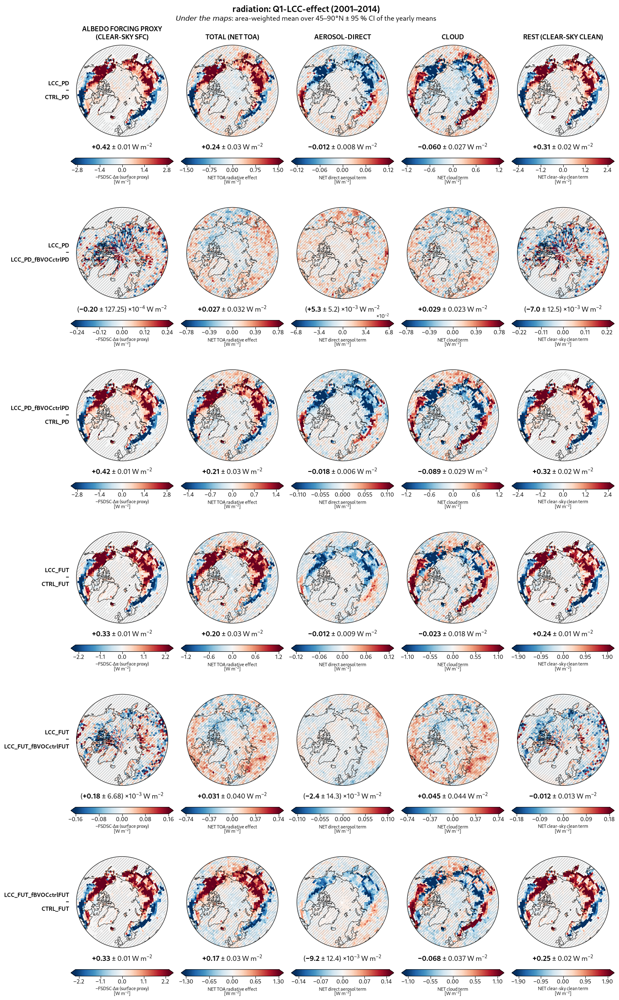

In [4]:
grid("Q1-LCC-effect", "radiation")

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/lcc-bvoc-background-contrast-maps/contrast_maps_uncorrected_outputs/figures/contrast_grid_bvoc-soa-cloud_Q1-LCC-effect_2001_2014.png


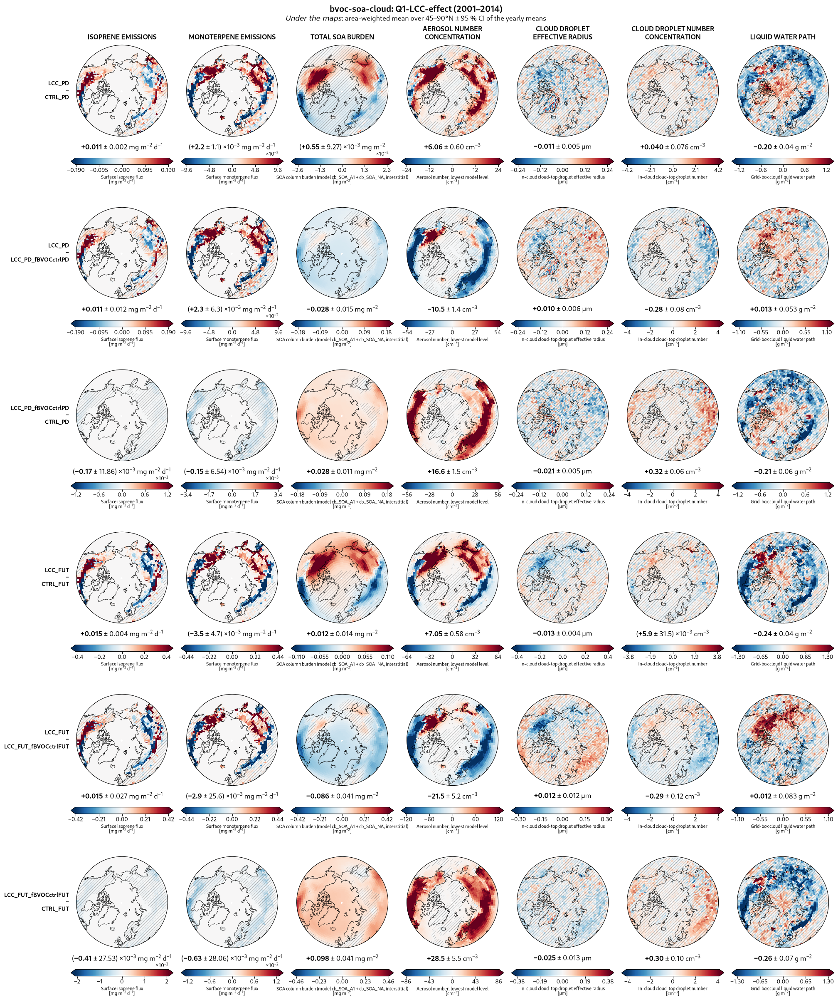

In [5]:
grid("Q1-LCC-effect", "bvoc-soa-cloud")

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/lcc-bvoc-background-contrast-maps/contrast_maps_uncorrected_outputs/figures/contrast_grid_surface_Q1-LCC-effect_2001_2014.png


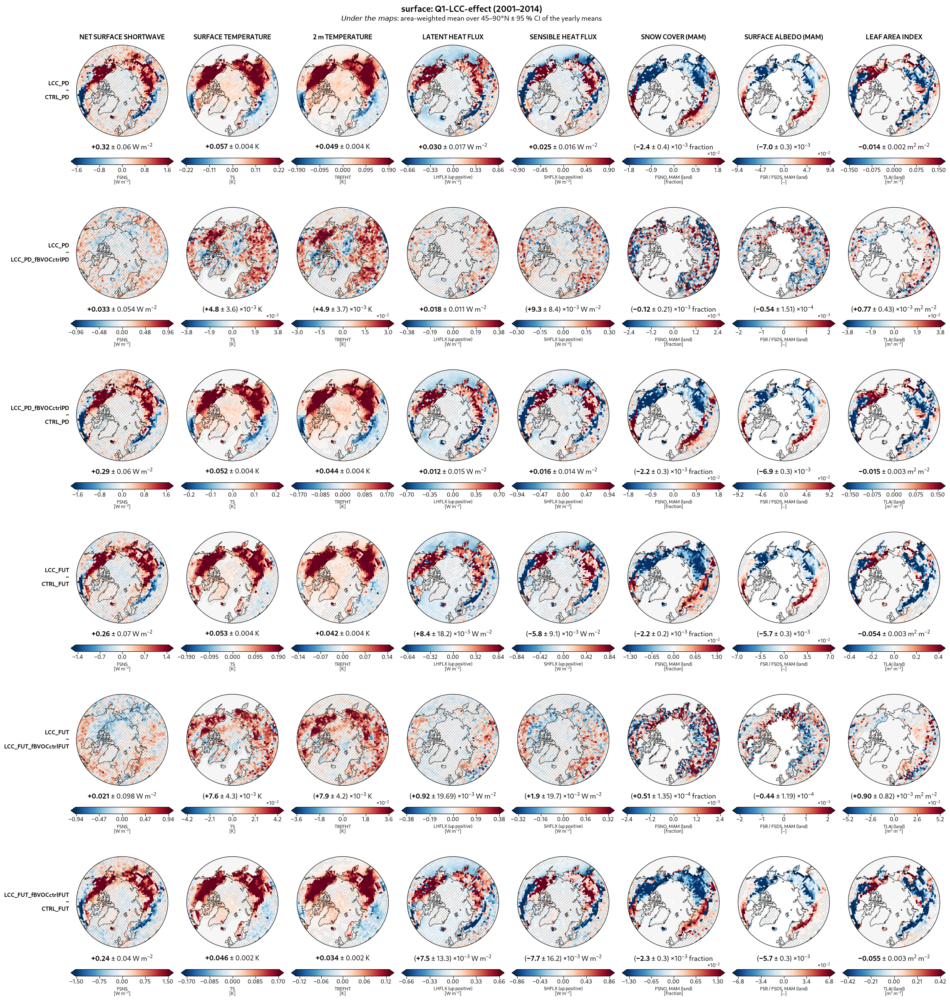

In [6]:
grid("Q1-LCC-effect", "surface")

## 2. What is the effect of changing the BVOC emission source in the future environment?
In every comparison below, both simulations use FUT conditions and changed land cover. What changes is the BVOC emission treatment.

| Row | Simulation difference | What it measures |
|---|---|---|
| 1 | `LCC_FUT_fBVOClccPD − LCC_FUT_fBVOCctrlPD` | Effect of the BVOC emission change caused by land-cover change in PD, applied under FUT conditions. Replaces prescribed CTRL_PD emissions with prescribed LCC_PD emissions. |
| 2 | `LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD` | Effect of the PD → FUT change in BVOC emissions from control land cover, applied under FUT conditions. Replaces prescribed CTRL_PD emissions with prescribed CTRL_FUT emissions. |
| 3 | `LCC_FUT − LCC_FUT_fBVOClccPD` | Effect of using FUT rather than PD BVOC emissions from changed land cover. Replaces prescribed LCC_PD emissions with interactive LCC_FUT emissions. |
| 4 | `LCC_FUT − LCC_FUT_fBVOCctrlPD` | Combined effect of moving from CTRL_PD BVOC emissions to interactive LCC_FUT emissions. Includes emission changes associated with both land-cover change and the PD → FUT environment, evaluated under FUT conditions with changed land cover. |

Row 3 is "FUT rather than PD emissions **from changed land cover**", not "emissions from changed vegetation": the prescribed fields differ over the whole domain, not only in the modified cells.

**Reading aid:** row 4 = row 1 + row 3 = row 2 + (`LCC_FUT − LCC_FUT_fBVOCctrlFUT`, Q1 row 5). Rows 1–2 compare two prescribed runs; rows 3–4 contain the artefact.

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/lcc-bvoc-background-contrast-maps/contrast_maps_uncorrected_outputs/figures/contrast_grid_radiation_Q2-FUT-emission-source_2001_2014.png


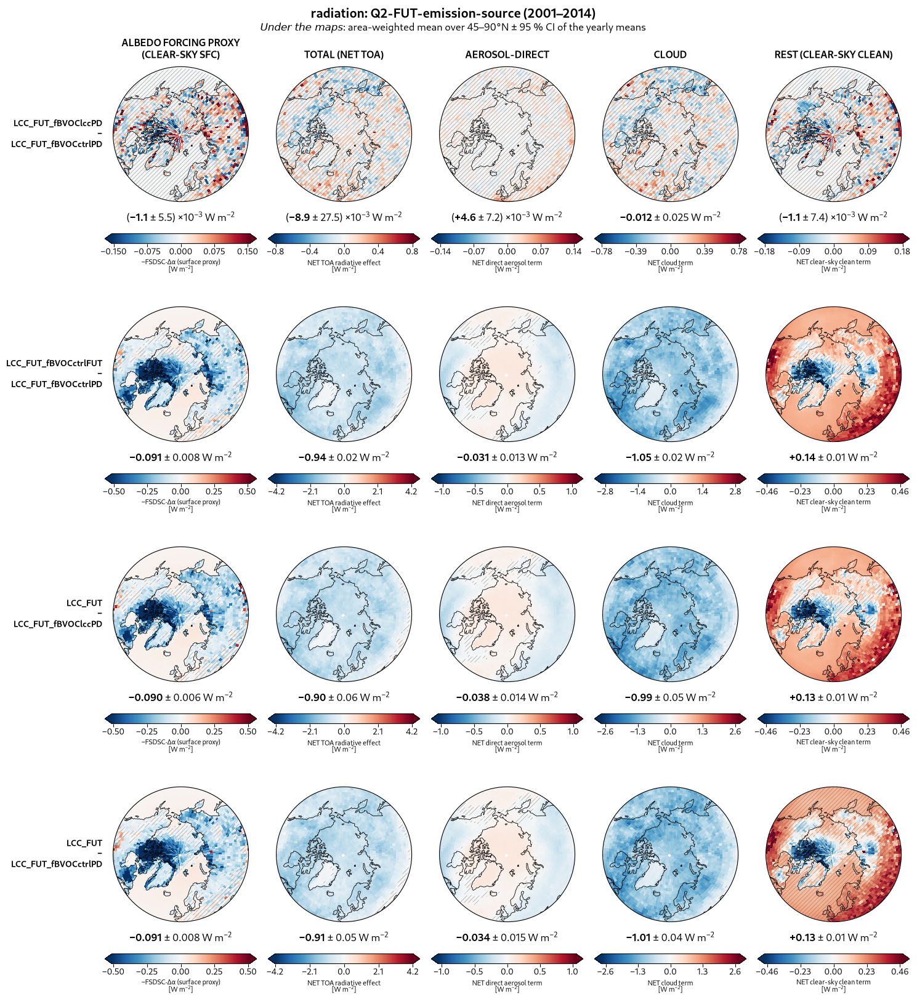

In [7]:
grid("Q2-FUT-emission-source", "radiation")

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/lcc-bvoc-background-contrast-maps/contrast_maps_uncorrected_outputs/figures/contrast_grid_bvoc-soa-cloud_Q2-FUT-emission-source_2001_2014.png


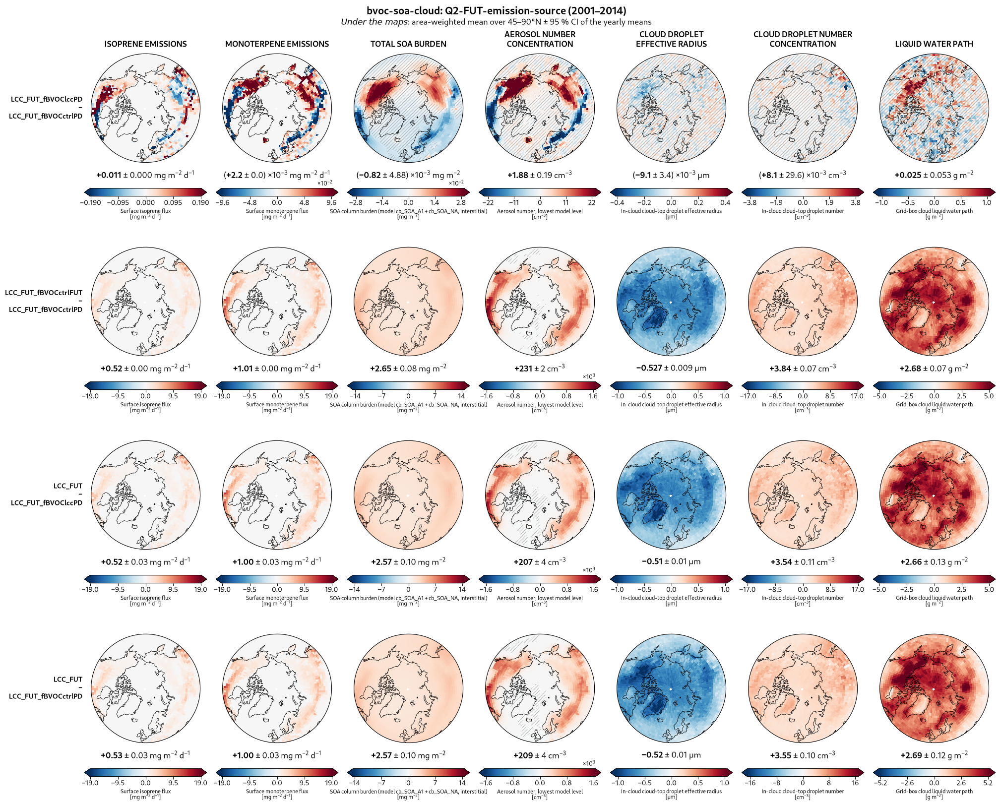

In [8]:
grid("Q2-FUT-emission-source", "bvoc-soa-cloud")

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/lcc-bvoc-background-contrast-maps/contrast_maps_uncorrected_outputs/figures/contrast_grid_surface_Q2-FUT-emission-source_2001_2014.png


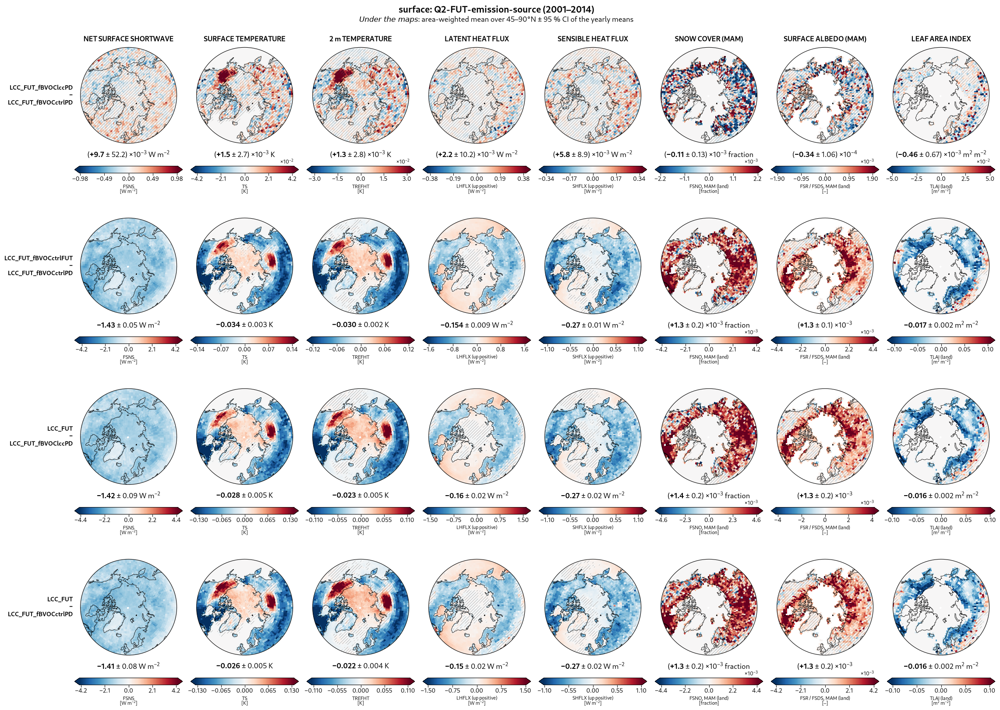

In [9]:
grid("Q2-FUT-emission-source", "surface")

## 3. What is the combined response to moving from PD to FUT?

| Row | Simulation difference | What it measures |
|---|---|---|
| 1 | `CTRL_FUT − CTRL_PD` | Response to the PD → FUT environment with control land cover retained. Includes all imposed background changes and the associated response of interactive BVOC emissions. |
| 2 | `LCC_FUT − LCC_PD` | Response to the PD → FUT environment with changed land cover retained. Includes all imposed background changes and the associated response of interactive BVOC emissions. |
| 3 | `LCC_FUT − CTRL_PD` | Combined response to the PD → FUT environment and land-cover change. Compares the PD control state with the FUT state containing changed land cover and interactive BVOC emissions. |

**Reading aid:** row 3 = row 1 + Q1 row 4 = row 2 + Q1 row 1. Row 2 − row 1 = Q1 row 4 − Q1 row 1 (how the LCC effect depends on the background). All runs are interactive: no artefact.

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/lcc-bvoc-background-contrast-maps/contrast_maps_uncorrected_outputs/figures/contrast_grid_radiation_Q3-PD-to-FUT_2001_2014.png


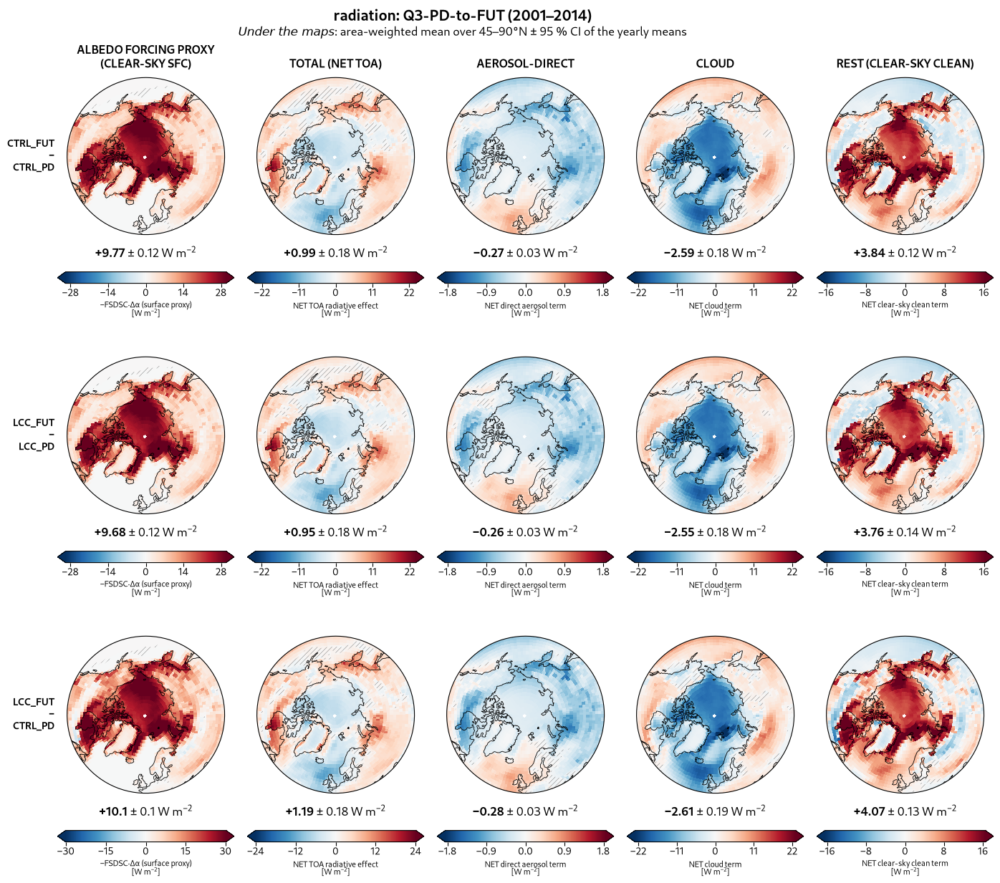

In [10]:
grid("Q3-PD-to-FUT", "radiation")

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/lcc-bvoc-background-contrast-maps/contrast_maps_uncorrected_outputs/figures/contrast_grid_bvoc-soa-cloud_Q3-PD-to-FUT_2001_2014.png


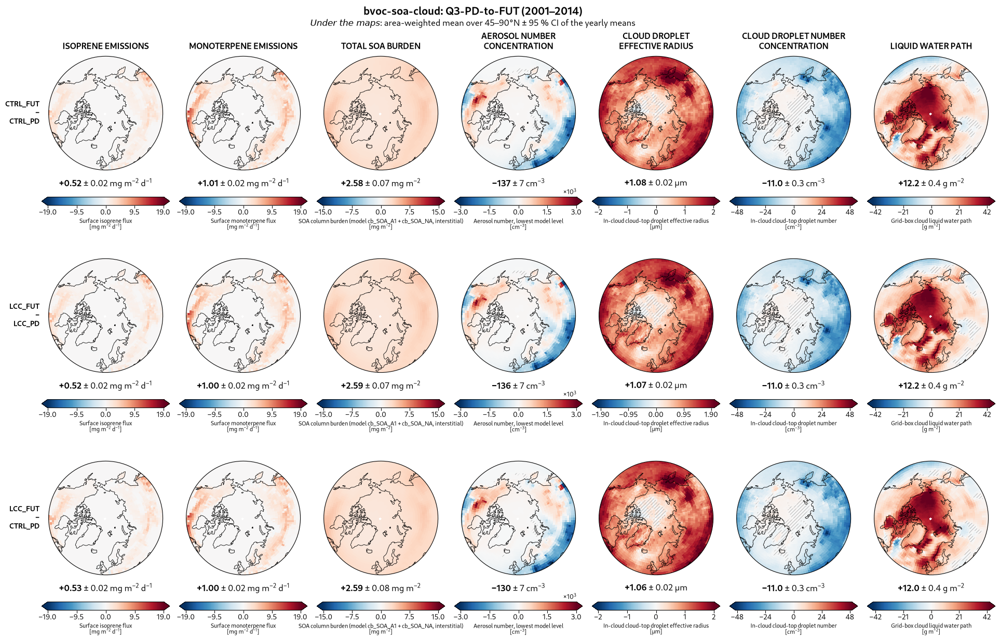

In [11]:
grid("Q3-PD-to-FUT", "bvoc-soa-cloud")

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/lcc-bvoc-background-contrast-maps/contrast_maps_uncorrected_outputs/figures/contrast_grid_surface_Q3-PD-to-FUT_2001_2014.png


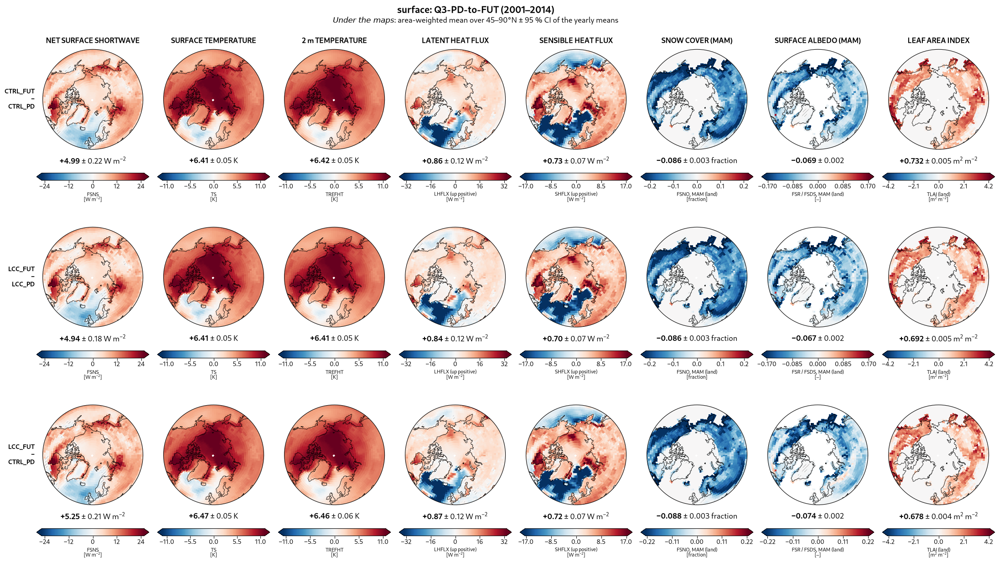

In [12]:
grid("Q3-PD-to-FUT", "surface")

## 4. Regional means (all contrasts)
Area-weighted mean over each region of the yearly differences; mean ± 95 % t-interval across the 14 years. Same fields as the maps (linear ones only, so §5 can check the sums).

In [13]:
TABLE_FIELDS = [("RADIATIVE", "NET_toa", "atm"), ("RADIATIVE", "NET_dir", "atm"), ("RADIATIVE", "NET_cloud", "atm"),
                ("RADIATIVE", "NET_rest", "atm"), ("BVOC", "SFISOP_mgm2d", "atm"), ("BVOC", "SFMTERP_mgm2d", "atm"),
                ("SOA", "cbSOA_mgm2", "atm"), ("METEO", "TS", "atm")]
REGIONS = ("≥45°N", "modified cells", "unmodified land ≥45°N")
ref = fm.open_class("CTRL_PD", "RADIATIVE", START_YEAR, END_YEAR)
masks = fm.region_masks(ref)

long = []
for q, rows in QUESTIONS.items():
    for i, (c1, c2, meaning) in enumerate(rows, 1):
        for cls, var, comp in TABLE_FIELDS:
            d = fm.yearly_difference(c1, c2, cls, var, START_YEAR, END_YEAR, comp)
            for region in REGIONS:
                r = fm.regional(d, ref, masks[region])
                long += [dict(question=q, row=i, contrast=f"{c1} − {c2}", field=var, region=region,
                              year=int(y), value=float(v)) for y, v in zip(r["year"].values, r.values)]
long = pd.DataFrame(long)
summary = fm.summarize_years(long, ["question", "row", "contrast", "field", "region"])
summary.to_csv(TABLES / f"regional_means_{START_YEAR}_{END_YEAR}.csv", index=False)

fmt = summary.assign(v=[f"{m:+.3g} ± {c:.2g}" for m, c in zip(summary["mean"], summary["ci95"])])
for region in ("≥45°N", "modified cells"):
    print(f"\n=== {region} ===")
    display(fmt[fmt.region == region].pivot_table(index=["question", "row", "contrast"], columns="field",
                                                  values="v", aggfunc="first")[[f for _, f, _ in TABLE_FIELDS]])


=== ≥45°N ===


field                                                                           NET_toa            NET_dir        NET_cloud           NET_rest       SFISOP_mgm2d       SFMTERP_mgm2d          cbSOA_mgm2  \
question               row contrast                                                                                                                                                                         
Q1-LCC-effect          1   LCC_PD − CTRL_PD                               +0.24 ± 0.031   -0.0124 ± 0.0076  -0.0601 ± 0.027     +0.312 ± 0.017   +0.0107 ± 0.0017   +0.00219 ± 0.0011  +0.000549 ± 0.0093   
                       2   LCC_PD − LCC_PD_fBVOCctrlPD                  +0.0274 ± 0.032  +0.00528 ± 0.0052  +0.0291 ± 0.023     -0.007 ± 0.012    +0.0109 ± 0.012   +0.00234 ± 0.0063     -0.0277 ± 0.015   
                       3   LCC_PD_fBVOCctrlPD − CTRL_PD                  +0.212 ± 0.034   -0.0177 ± 0.0061  -0.0893 ± 0.029     +0.319 ± 0.017  -0.000166 ± 0.012  -0.000148 ± 0.0065     +0.0283 ± 0.011   
                       4   LCC_FUT − CTRL_FUT                              +0.2 ± 0.029   -0.0116 ± 0.0088  -0.0228 ± 0.018     +0.235 ± 0.011   +0.0145 ± 0.0037   -0.00348 ± 0.0047     +0.0123 ± 0.014   
                       5   LCC_FUT − LCC_FUT_fBVOCctrlFUT                 +0.031 ± 0.04   -0.00244 ± 0.014  +0.0452 ± 0.044    -0.0118 ± 0.013    +0.0149 ± 0.027    -0.00285 ± 0.026     -0.0861 ± 0.041   
                       6   LCC_FUT_fBVOCctrlFUT − CTRL_FUT                +0.17 ± 0.031   -0.00919 ± 0.012   -0.068 ± 0.037     +0.247 ± 0.021  -0.000412 ± 0.028   -0.000625 ± 0.028     +0.0983 ± 0.041   
Q2-FUT-emission-source 1   LCC_FUT_fBVOClccPD − LCC_FUT_fBVOCctrlPD    -0.00889 ± 0.028  +0.00455 ± 0.0072  -0.0124 ± 0.025  -0.00104 ± 0.0074        +0.0107 ± 0        +0.00219 ± 0  -0.000817 ± 0.0049   
                       2   LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD    -0.939 ± 0.023    -0.0312 ± 0.013    -1.05 ± 0.024     +0.144 ± 0.013         +0.519 ± 0           +1.01 ± 0       +2.65 ± 0.079   
                       3   LCC_FUT − LCC_FUT_fBVOClccPD                  -0.899 ± 0.057    -0.0382 ± 0.014   -0.994 ± 0.051     +0.133 ± 0.011     +0.523 ± 0.027          +1 ± 0.026         +2.57 ± 0.1   
                       4   LCC_FUT − LCC_FUT_fBVOCctrlPD                 -0.908 ± 0.049    -0.0336 ± 0.015    -1.01 ± 0.043     +0.132 ± 0.013     +0.534 ± 0.027          +1 ± 0.026         +2.57 ± 0.1   
Q3-PD-to-FUT           1   CTRL_FUT − CTRL_PD                             +0.984 ± 0.18     -0.266 ± 0.031     -2.59 ± 0.18       +3.84 ± 0.12     +0.519 ± 0.017       +1.01 ± 0.022       +2.58 ± 0.073   
                       2   LCC_FUT − LCC_PD                               +0.945 ± 0.18     -0.265 ± 0.034     -2.55 ± 0.18       +3.76 ± 0.14     +0.523 ± 0.016           +1 ± 0.02       +2.59 ± 0.071   
                       3   LCC_FUT − CTRL_PD                               +1.18 ± 0.18     -0.277 ± 0.033     -2.62 ± 0.19       +4.08 ± 0.13     +0.533 ± 0.016           +1 ± 0.02       +2.59 ± 0.078   

field                                                                                 TS  
question               row contrast                                                       
Q1-LCC-effect          1   LCC_PD − CTRL_PD                             +0.0573 ± 0.0041  
                       2   LCC_PD − LCC_PD_fBVOCctrlPD                 +0.00482 ± 0.0036  
                       3   LCC_PD_fBVOCctrlPD − CTRL_PD                  +0.0524 ± 0.004  
                       4   LCC_FUT − CTRL_FUT                           +0.0534 ± 0.0038  
                       5   LCC_FUT − LCC_FUT_fBVOCctrlFUT              +0.00758 ± 0.0043  
                       6   LCC_FUT_fBVOCctrlFUT − CTRL_FUT              +0.0458 ± 0.0025  
Q2-FUT-emission-source 1   LCC_FUT_fBVOClccPD − LCC_FUT_fBVOCctrlPD     +0.0015 ± 0.0027  
                       2   LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD    -0.034 ± 0.0026  
              


=== modified cells ===


field                                                                          NET_toa            NET_dir        NET_cloud           NET_rest       SFISOP_mgm2d      SFMTERP_mgm2d         cbSOA_mgm2                 TS
question               row contrast                                                                                                                                                                                      
Q1-LCC-effect          1   LCC_PD − CTRL_PD                              +0.541 ± 0.04   -0.0316 ± 0.0073   -0.205 ± 0.039     +0.777 ± 0.035   +0.0228 ± 0.0032  +0.00333 ± 0.0019  +0.00387 ± 0.0092    +0.138 ± 0.0051
                       2   LCC_PD − LCC_PD_fBVOCctrlPD                 +0.0375 ± 0.049  +0.00418 ± 0.0047  +0.0455 ± 0.043     -0.0122 ± 0.02     +0.023 ± 0.019   +0.00356 ± 0.011     -0.023 ± 0.016    +0.0105 ± 0.006
                       3   LCC_PD_fBVOCctrlPD − CTRL_PD                 +0.503 ± 0.046   -0.0357 ± 0.0067   -0.251 ± 0.033       +0.79 ± 0.04  -0.000186 ± 0.017  -0.000224 ± 0.011    +0.0269 ± 0.011    +0.127 ± 0.0058
                       4   LCC_FUT − CTRL_FUT                             +0.5 ± 0.051   -0.0265 ± 0.0077   -0.076 ± 0.041     +0.603 ± 0.023   +0.0343 ± 0.0069   -0.0113 ± 0.0093    +0.0218 ± 0.013    +0.131 ± 0.0072
                       5   LCC_FUT − LCC_FUT_fBVOCctrlFUT              +0.0343 ± 0.057   -0.00203 ± 0.012  +0.0569 ± 0.059    -0.0206 ± 0.013    +0.0349 ± 0.046    -0.0103 ± 0.047    -0.0695 ± 0.044   +0.0126 ± 0.0063
                       6   LCC_FUT_fBVOCctrlFUT − CTRL_FUT              +0.466 ± 0.034     -0.0245 ± 0.01   -0.133 ± 0.037      +0.623 ± 0.03  -0.000562 ± 0.045   -0.00102 ± 0.049    +0.0914 ± 0.043    +0.119 ± 0.0051
Q2-FUT-emission-source 1   LCC_FUT_fBVOClccPD − LCC_FUT_fBVOCctrlPD     -0.0252 ± 0.03  +0.00295 ± 0.0066   -0.0228 ± 0.03  -0.00535 ± 0.0097        +0.0228 ± 0       +0.00333 ± 0  +0.00299 ± 0.0048  +0.00391 ± 0.0047
                       2   LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD    -1.14 ± 0.033    -0.0553 ± 0.012    -1.17 ± 0.041    +0.0859 ± 0.016         +0.793 ± 0          +1.67 ± 0       +2.8 ± 0.081    -0.0447 ± 0.006
                       3   LCC_FUT − LCC_FUT_fBVOClccPD                   -1.08 ± 0.07    -0.0602 ± 0.014    -1.09 ± 0.064    +0.0707 ± 0.012     +0.805 ± 0.046      +1.66 ± 0.047       +2.73 ± 0.11    -0.036 ± 0.0083
                       4   LCC_FUT − LCC_FUT_fBVOCctrlPD                 -1.11 ± 0.071    -0.0573 ± 0.013    -1.11 ± 0.065    +0.0653 ± 0.017     +0.828 ± 0.046      +1.66 ± 0.047       +2.73 ± 0.11    -0.0321 ± 0.008
Q3-PD-to-FUT           1   CTRL_FUT − CTRL_PD                             +2.62 ± 0.28     -0.434 ± 0.026    -0.565 ± 0.39       +3.62 ± 0.22      +0.794 ± 0.03       +1.67 ± 0.04      +2.73 ± 0.082      +7.76 ± 0.092
                       2   LCC_FUT − LCC_PD                               +2.58 ± 0.27     -0.429 ± 0.028    -0.436 ± 0.37       +3.45 ± 0.21      +0.805 ± 0.03      +1.66 ± 0.038      +2.74 ± 0.081      +7.75 ± 0.093
                       3   LCC_FUT − CTRL_PD                              +3.13 ± 0.27     -0.461 ± 0.028    -0.641 ± 0.39       +4.23 ± 0.23     +0.828 ± 0.031      +1.66 ± 0.038      +2.75 ± 0.087      +7.89 ± 0.094

## 5. Additivity check (reading aids above)
Yearly regional means are linear in the runs, so each identity must close to rounding error. A non-zero residual means a wrong alias or a mismatched file.

In [14]:
def val(c):
    return long[long.contrast == c].set_index(["field", "region", "year"])["value"]

IDENTITIES = {
    "Q1 PD: row1 = row2 + row3": ("LCC_PD − CTRL_PD", ["LCC_PD − LCC_PD_fBVOCctrlPD", "LCC_PD_fBVOCctrlPD − CTRL_PD"]),
    "Q1 FUT: row4 = row5 + row6": ("LCC_FUT − CTRL_FUT", ["LCC_FUT − LCC_FUT_fBVOCctrlFUT", "LCC_FUT_fBVOCctrlFUT − CTRL_FUT"]),
    "Q2: row4 = row1 + row3": ("LCC_FUT − LCC_FUT_fBVOCctrlPD", ["LCC_FUT_fBVOClccPD − LCC_FUT_fBVOCctrlPD", "LCC_FUT − LCC_FUT_fBVOClccPD"]),
    "Q2: row4 = row2 + Q1 row5": ("LCC_FUT − LCC_FUT_fBVOCctrlPD", ["LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD", "LCC_FUT − LCC_FUT_fBVOCctrlFUT"]),
    "Q3: row3 = row1 + Q1 row4": ("LCC_FUT − CTRL_PD", ["CTRL_FUT − CTRL_PD", "LCC_FUT − CTRL_FUT"]),
    "Q3: row3 = row2 + Q1 row1": ("LCC_FUT − CTRL_PD", ["LCC_FUT − LCC_PD", "LCC_PD − CTRL_PD"]),
}
check = pd.DataFrame([dict(identity=k, max_abs_residual=float((val(lhs) - sum(val(c) for c in rhs)).abs().max()))
                      for k, (lhs, rhs) in IDENTITIES.items()])
check

,identity,max_abs_residual
0,Q1 PD: row1 = row2 + row3,8.881784e-16
1,Q1 FUT: row4 = row5 + row6,8.881784e-16
2,Q2: row4 = row1 + row3,4.884981e-15
3,Q2: row4 = row2 + Q1 row5,7.549517e-15
4,Q3: row3 = row1 + Q1 row4,1.953993e-14
5,Q3: row3 = row2 + Q1 row1,1.598721e-14
